# ¿Cuánto difieren dos instrumentos?

**Andrés Monreal Ciencia · Cuaderno reproducible · versión 0.1.0**

En esta práctica compararás dos métodos que leen la misma magnitud en la misma unidad. Reproduce los tres ejemplos de la [versión web del laboratorio](https://sircalch.github.io/es/herramientas/concordancia/) y prueba después con un archivo propio. Los ejemplos tienen ocho pares sintéticos cada uno.

**Para empezar.** Abre este archivo en Jupyter con un kernel de Python 3.10 o posterior y Matplotlib 3.7 o posterior instalado. Ejecuta las celdas en orden. Las dos primeras partes se ejecutan con los datos incluidos en el cuaderno.

## 1. Calcula las diferencias

Para cada par calcula el promedio `(A + B) / 2` y la diferencia `B − A`. El sesgo es la media de esas diferencias. Los límites estimados son el sesgo ± 1.96 veces la desviación estándar muestral de las diferencias. El recuento dentro de la tolerancia describe solamente los pares observados.

In [1]:
from math import isfinite, isclose, sqrt
from statistics import correlation, mean, stdev


def concordancia(pares, tolerancia=None):
    pares = [(float(a), float(b)) for a, b in pares]
    if not 3 <= len(pares) <= 1000:
        raise ValueError("Introduce entre 3 y 1000 pares.")
    if any(not isfinite(x) or abs(x) > 1e9 for par in pares for x in par):
        raise ValueError("Usa números finitos con magnitud de hasta 1000 millones.")
    if tolerancia is not None and not (isfinite(tolerancia) and 0 <= tolerancia <= 1e9):
        raise ValueError("Usa una tolerancia en el intervalo de 0 a 1000 millones.")

    a, b = zip(*pares)
    promedios = [(x + y) / 2 for x, y in pares]
    diferencias = [y - x for x, y in pares]
    sesgo = mean(diferencias)
    desviacion = stdev(diferencias)
    amplitud = 1.96 * desviacion
    r = correlation(a, b) if min(a) != max(a) and min(b) != max(b) else None
    dentro = None if tolerancia is None else sum(abs(d) <= tolerancia for d in diferencias)
    return {
        "n": len(pares), "sesgo": sesgo, "desviacion": desviacion, "pearson": r,
        "inferior": sesgo - amplitud, "superior": sesgo + amplitud,
        "dentro": dentro, "promedios": promedios, "diferencias": diferencias,
    }

## 2. Reproduce los casos publicados

Antes de mirar la salida, predice qué ocurrirá con Pearson al sumar 5 a todas las lecturas de B. Elige ±2 unidades como tolerancia para esta práctica de banco.

In [2]:
lecturas = list(range(10, 81, 10))
ejemplos = {
    "Desplazamiento constante": [(a, a + 5) for a in lecturas],
    "Diferencia proporcional": [(a, a + a // 10) for a in lecturas],
    "Variación alrededor de cero": list(zip(lecturas, [9, 21, 28, 40, 50, 62, 71, 79])),
}

tolerancia = 2
resultados = {caso: concordancia(pares, tolerancia) for caso, pares in ejemplos.items()}
for caso, m in resultados.items():
    print(f"{caso}: r={m['pearson']:.4f}, sesgo={m['sesgo']:+.4f}, "
          f"límites [{m['inferior']:+.4f}, {m['superior']:+.4f}], "
          f"dentro de ±{tolerancia}: {m['dentro']}/{m['n']}")

constante, proporcional, variable = resultados.values()
assert isclose(constante["pearson"], 1) and constante["sesgo"] == 5 and constante["dentro"] == 0
assert proporcional["sesgo"] == 4.5 and proporcional["dentro"] == 2
assert variable["sesgo"] == 0 and variable["dentro"] == 8
assert isclose(variable["superior"], 1.96 * sqrt(12 / 7), rel_tol=1e-12)
assert concordancia([(1, 4), (1, 5), (1, 6)])["pearson"] is None
assert concordancia([(1, 1), (2, 2), (3, 3)], 0)["dentro"] == 3

Desplazamiento constante: r=1.0000, sesgo=+5.0000, límites [+5.0000, +5.0000], dentro de ±2: 0/8
Diferencia proporcional: r=1.0000, sesgo=+4.5000, límites [-0.3010, +9.3010], dentro de ±2: 2/8
Variación alrededor de cero: r=0.9987, sesgo=+0.0000, límites [-2.5662, +2.5662], dentro de ±2: 8/8


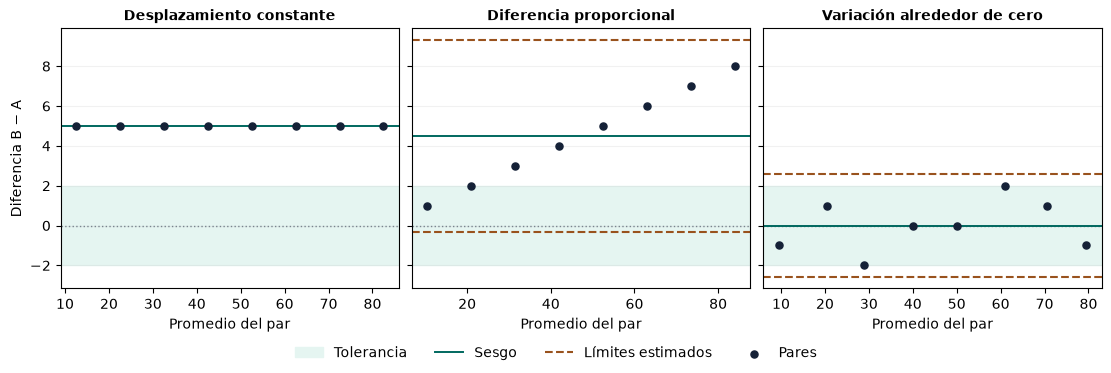

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt


def dibujar_concordancia(eje, datos, tolerancia):
    if tolerancia is not None:
        eje.axhspan(-tolerancia, tolerancia, color="#e5f5f1", label="Tolerancia")
    eje.axhline(0, color="#79848e", linestyle=":", linewidth=1)
    eje.axhline(datos["sesgo"], color="#00685f", linewidth=1.4, label="Sesgo")
    if datos["inferior"] != datos["superior"]:
        eje.axhline(datos["inferior"], color="#99521d", linestyle="--", label="Límites estimados")
        eje.axhline(datos["superior"], color="#99521d", linestyle="--")
    eje.scatter(datos["promedios"], datos["diferencias"], color="#152137", s=26, zorder=4, label="Pares")
    eje.set_xlabel("Promedio del par")
    eje.grid(axis="y", alpha=0.17)


figura, ejes = plt.subplots(1, 3, figsize=(11, 3.65), sharey=True, layout="constrained")
for eje, (caso, datos) in zip(ejes, resultados.items()):
    dibujar_concordancia(eje, datos, tolerancia)
    eje.set_title(caso, fontsize=10, fontweight="bold")
eje_inicial = ejes[0]
eje_inicial.set_ylabel("Diferencia B − A")
figura.legend(*ejes[1].get_legend_handles_labels(), loc="outside lower center", ncols=4, frameon=False)
plt.show()

El desplazamiento constante mantiene una correlación perfecta y produce un sesgo de +5. En el ejemplo proporcional se ve una tendencia de las diferencias con la magnitud. En el último ejemplo, los ocho pares cumplen la tolerancia elegida y los límites estimados alcanzan aproximadamente ±2.57. Esos indicadores contestan preguntas distintas.

Los límites aproximados del 95 % se interpretan bajo pares independientes y diferencias aproximadamente normales y de dispersión estable. Con datos reales, revisa primero el patrón, incluidos valores extremos y cambios de dispersión. La tolerancia se justifica a partir del uso de la medición. Los ejemplos de ocho pares son didácticos y corresponden a una comparación de banco.

## 3. Analiza un archivo propio

Acepta encabezados `metodo_a` y `metodo_b`, incluidos los CSV descargados del laboratorio. Pon punto decimal con separador coma o coma decimal con separador punto y coma. Conserva un par por fila, en la misma unidad. Para probar la lectura, el archivo incluido `mediciones-ejemplo.csv` contiene el caso de variación alrededor de cero.

In [4]:
import csv
from pathlib import Path


def cargar_pares(ruta):
    with Path(ruta).open(encoding="utf-8-sig", newline="") as archivo:
        cabecera = archivo.readline()
        delimitador = ";" if ";" in cabecera else ","
        archivo.seek(0)
        filas = csv.DictReader(archivo, delimiter=delimitador)
        if not {"metodo_a", "metodo_b"}.issubset(filas.fieldnames or []):
            raise ValueError("Usa los encabezados metodo_a y metodo_b.")
        pares = []
        for fila in filas:
            try:
                campos = [fila[nombre] for nombre in ("metodo_a", "metodo_b")]
                if None in campos or None in fila:
                    raise ValueError("Columnas incompletas o adicionales")
                a, b = (float(x.replace(",", ".") if delimitador == ";" else x) for x in campos)
            except (TypeError, ValueError) as error:
                raise ValueError(f"Revisa los dos números de la fila {filas.line_num}.") from error
            pares.append((a, b))
    return pares


archivo_propio = None  # Cambia a Path("mediciones-ejemplo.csv") o señala tu CSV.
if archivo_propio is not None:
    datos_propios = concordancia(cargar_pares(archivo_propio), tolerancia)
    print({clave: valor for clave, valor in datos_propios.items()
           if clave not in ("promedios", "diferencias")})
    figura, eje = plt.subplots(figsize=(6.7, 3.8), layout="constrained")
    dibujar_concordancia(eje, datos_propios, tolerancia)
    eje.set_ylabel("Diferencia B − A")
    figura.legend(*eje.get_legend_handles_labels(), loc="outside lower center", ncols=4, frameon=False)
    plt.show()

## Entrega de la práctica

1. Explica por qué `r = 1` puede coexistir con una diferencia constante de cinco unidades.
2. Señala en el gráfico la evidencia de diferencia proporcional y explica por qué un único sesgo puede ocultar el patrón.
3. Cambia la tolerancia a ±1 en el caso variable y vuelve a obtener el recuento. Registra la versión del cuaderno, unidad, tolerancia y motivo de tu elección.

### Fuentes del método

- Bland, J. M. y Altman, D. G. (1986). *Statistical methods for assessing agreement between two methods of clinical measurement*. The Lancet, 1(8476), 307–310. [Texto de los autores](https://www-users.york.ac.uk/~mb55/meas/ba.htm).
- Bland, J. M. y Altman, D. G. (1999). *Measuring agreement in method comparison studies*. Statistical Methods in Medical Research, 8(2), 135–160. [Registro de la publicación](https://pubmed.ncbi.nlm.nih.gov/10501650/).